In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [40]:
# def formatData(val):
#     return f'{val} µg/m³'

# def plotData(dataframe, col_name, prefix='', ha_point='center', va_point='bottom'):
#     for idx, val in enumerate(dataframe[col_name]):
#         formatted_val = f'{prefix}'+formatData(val)
#         plt.text(idx, val, formatted_val, ha=ha_point, va=va_point)

## 1. Data Analysis and visualization of last 30 days data

In [3]:
df30 = pd.read_csv('cleaned_bagdolLast30days.csv')
df30

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6230465,Bagdol,pm25,23.8,µg/m³,2026-09-12 06:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-09-12,06:45:00
1,6230465,Bagdol,pm25,29.0,µg/m³,2026-09-12 07:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-09-12,07:45:00
2,6230465,Bagdol,pm25,32.0,µg/m³,2026-09-12 08:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-09-12,08:45:00
3,6230465,Bagdol,pm25,33.3,µg/m³,2026-09-12 09:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-09-12,09:45:00
4,6230465,Bagdol,pm25,25.3,µg/m³,2026-09-12 10:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-09-12,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
714,6230465,Bagdol,pm25,33.6,µg/m³,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-12,01:45:00
715,6230465,Bagdol,pm25,31.9,µg/m³,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-12,02:45:00
716,6230465,Bagdol,pm25,32.0,µg/m³,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-12,03:45:00
717,6230465,Bagdol,pm25,32.4,µg/m³,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-12,04:45:00


In [4]:
df30['date'].unique()

<ArrowStringArray>
['2026-09-12', '2026-09-13', '2026-09-14', '2026-09-15', '2026-09-16',
 '2026-09-17', '2026-09-18', '2026-09-19', '2026-09-20', '2026-09-21',
 '2026-09-22', '2026-09-23', '2026-09-24', '2026-09-25', '2026-09-26',
 '2026-09-27', '2026-09-28', '2026-09-29', '2026-09-30', '2026-10-01',
 '2026-10-02', '2026-10-03', '2026-10-04', '2026-10-05', '2026-10-06',
 '2026-10-07', '2026-10-08', '2026-10-09', '2026-10-10', '2026-10-11',
 '2026-10-12']
Length: 31, dtype: str

#### Aggrigating hourly data to daily means, and filling only short gaps(1 to 2 days) by interpolation

In [5]:
# 1. Load hourly data observations
hourly = df30

# Ensure date and PM2.5 values have appropriate types
hourly['date'] = pd.to_datetime(hourly['date'])
hourly['value'] = pd.to_numeric(hourly['value'], errors='coerce')

In [6]:
# 2-3. Aggrigate available hourly PM2.5 values to daily means
daily = (
    hourly.dropna(subset=['date', 'value'])
    .groupby('date', as_index=True)
    .agg(
        pm25_daily_mean_ug_m3=('date', 'mean'),
        hourly_observation_count=('value', 'count'),
    )
    .sort_index()
)

In [7]:
# 4. Include every calendar day in the observed date range
all_days = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
daily = daily.reindex(all_days)
daily.index.name = "date"

In [8]:
# Mark original observed daily means
daily["fill_method"] = "observed"
daily.loc[daily["pm25_daily_mean_ug_m3"].isna(), "fill_method"] = "missing_long_gap"

In [9]:
# 5–6. Identify missing runs and interpolate only 1–2 day gaps
missing = daily["pm25_daily_mean_ug_m3"].isna()
run_id = missing.ne(missing.shift()).cumsum()

for _, run_mask in missing.groupby(run_id):
    if not run_mask.iloc[0]:
        continue  # This run contains observed data, not missing data

    gap_dates = run_mask.index[run_mask]
    gap_length = len(gap_dates)

    # Only fill gaps lasting one or two days and bounded by observed values
    if gap_length in (1, 2):
        first_pos = daily.index.get_loc(gap_dates[0])
        last_pos = daily.index.get_loc(gap_dates[-1])

        has_left_neighbor = first_pos > 0
        has_right_neighbor = last_pos < len(daily.index) - 1

        if has_left_neighbor and has_right_neighbor:
            left_value = daily.iloc[first_pos - 1]["pm25_daily_mean_ug_m3"]
            right_value = daily.iloc[last_pos + 1]["pm25_daily_mean_ug_m3"]

            if pd.notna(left_value) and pd.notna(right_value):
                # Linear interpolation between the two surrounding daily means
                interpolated = daily["pm25_daily_mean_ug_m3"].interpolate(
                    method="linear",
                    limit=2,
                    limit_area="inside",
                )
                daily.loc[gap_dates, "pm25_daily_mean_ug_m3"] = interpolated.loc[gap_dates]
                daily.loc[gap_dates, "hourly_observation_count"] = 0
                daily.loc[gap_dates, "fill_method"] = "linear_interpolation"

In [10]:
# 7. Write a tidy CSV
daily = daily.reset_index()
daily["date"] = daily["date"].dt.strftime("%Y-%m-%d")


In [11]:
# output_file= 'bagdolAGGRIGATE.csv'

In [12]:
# daily.to_csv(
#     output_file,
#     index=False,
#     float_format="%.6f",
# )

In [11]:
daily

,date,pm25_daily_mean_ug_m3,hourly_observation_count,fill_method
0,2026-09-12,2026-09-12,18,observed
1,2026-09-13,2026-09-13,24,observed
2,2026-09-14,2026-09-14,24,observed
3,2026-09-15,2026-09-15,24,observed
4,2026-09-16,2026-09-16,24,observed
5,2026-09-17,2026-09-17,24,observed
6,2026-09-18,2026-09-18,24,observed
7,2026-09-19,2026-09-19,23,observed
8,2026-09-20,2026-09-20,24,observed
9,2026-09-21,2026-09-21,24,observed


In [12]:
daily.columns

Index(['date', 'pm25_daily_mean_ug_m3', 'hourly_observation_count',
       'fill_method'],
      dtype='str')

#### Plotting daily aggrigate value

/tmp/ipykernel_6916/3823274556.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


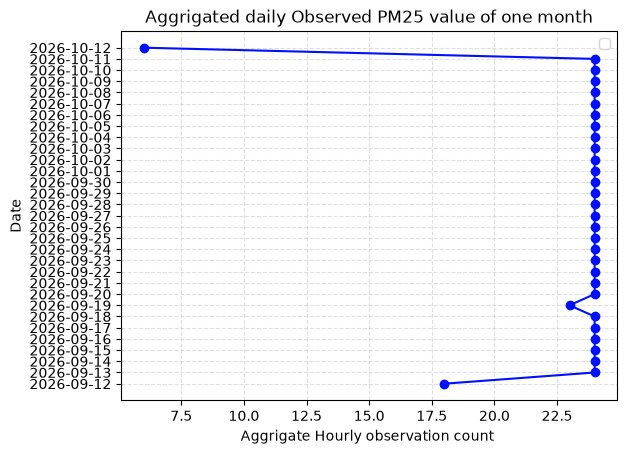

In [13]:
# Line plot
plt.plot(daily['hourly_observation_count'], daily['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count ')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed PM25 value of one month")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 2. Data Analysis and Visualization of last 7 days

In [14]:
df7 = pd.read_csv('cleaned_bagdolLast7days.csv')
df7

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6230465,Bagdol,pm25,48.7,µg/m³,2026-10-05 06:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-05,06:45:00
1,6230465,Bagdol,pm25,47.8,µg/m³,2026-10-05 07:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-05,07:45:00
2,6230465,Bagdol,pm25,48.4,µg/m³,2026-10-05 08:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-05,08:45:00
3,6230465,Bagdol,pm25,48.4,µg/m³,2026-10-05 09:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-05,09:45:00
4,6230465,Bagdol,pm25,42.8,µg/m³,2026-10-05 10:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-05,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,6230465,Bagdol,pm25,33.6,µg/m³,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-12,01:45:00
164,6230465,Bagdol,pm25,31.9,µg/m³,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-12,02:45:00
165,6230465,Bagdol,pm25,32.0,µg/m³,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-12,03:45:00
166,6230465,Bagdol,pm25,32.4,µg/m³,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-12,04:45:00


In [15]:
df7['date'].unique()

<ArrowStringArray>
['2026-10-05', '2026-10-06', '2026-10-07', '2026-10-08', '2026-10-09',
 '2026-10-10', '2026-10-11', '2026-10-12']
Length: 8, dtype: str

### Aggrigating hourly data to daily means, and filling only short gaps by interpolation

In [16]:
# 1. Load hourly data observations
hourly1 = df7

# Ensure date and PM2.5 values have appropriate types
hourly1['date'] = pd.to_datetime(hourly1['date'])
hourly1['value'] = pd.to_numeric(hourly1['value'], errors='coerce')

In [17]:
# 2-3. Aggrigate available hourly PM2.5 values to daily means
daily1 = (
    hourly1.dropna(subset=['date', 'value'])
    .groupby('date', as_index=True)
    .agg(
        pm25_daily_mean_ug_m3=('date', 'mean'),
        hourly_observation_count=('value', 'count'),
    )
    .sort_index()
)

In [18]:
# 4. Include every calendar day in the observed date range
all_days = pd.date_range(daily1.index.min(), daily1.index.max(), freq="D")
daily1 = daily1.reindex(all_days)
daily1.index.name = "date"

In [19]:
# Mark original observed daily means
daily1["fill_method"] = "observed"
daily1.loc[daily1["pm25_daily_mean_ug_m3"].isna(), "fill_method"] = "missing_long_gap"

In [20]:
# 5–6. Identify missing runs and interpolate only 1–2 day gaps
missing = daily1["pm25_daily_mean_ug_m3"].isna()
run_id = missing.ne(missing.shift()).cumsum()

for _, run_mask in missing.groupby(run_id):
    if not run_mask.iloc[0]:
        continue  # This run contains observed data, not missing data

    gap_dates = run_mask.index[run_mask]
    gap_length = len(gap_dates)

    # Only fill gaps lasting one or two days and bounded by observed values
    if gap_length in (1, 2):
        first_pos = daily1.index.get_loc(gap_dates[0])
        last_pos = daily1.index.get_loc(gap_dates[-1])

        has_left_neighbor = first_pos > 0
        has_right_neighbor = last_pos < len(daily1.index) - 1

        if has_left_neighbor and has_right_neighbor:
            left_value = daily1.iloc[first_pos - 1]["pm25_daily_mean_ug_m3"]
            right_value = daily1.iloc[last_pos + 1]["pm25_daily_mean_ug_m3"]

            if pd.notna(left_value) and pd.notna(right_value):
                # Linear interpolation between the two surrounding daily means
                interpolated = daily1["pm25_daily_mean_ug_m3"].interpolate(
                    method="linear",
                    limit=2,
                    limit_area="inside",
                )
                daily1.loc[gap_dates, "pm25_daily_mean_ug_m3"] = interpolated.loc[gap_dates]
                daily1.loc[gap_dates, "hourly_observation_count"] = 0
                daily1.loc[gap_dates, "fill_method"] = "linear_interpolation"

In [21]:
# 7. Write a tidy CSV
daily1 = daily1.reset_index()
daily1["date"] = daily1["date"].dt.strftime("%Y-%m-%d")

In [22]:
daily1

,date,pm25_daily_mean_ug_m3,hourly_observation_count,fill_method
0,2026-10-05,2026-10-05,18,observed
1,2026-10-06,2026-10-06,24,observed
2,2026-10-07,2026-10-07,24,observed
3,2026-10-08,2026-10-08,24,observed
4,2026-10-09,2026-10-09,24,observed
5,2026-10-10,2026-10-10,24,observed
6,2026-10-11,2026-10-11,24,observed
7,2026-10-12,2026-10-12,6,observed


In [23]:
daily1.columns

Index(['date', 'pm25_daily_mean_ug_m3', 'hourly_observation_count',
       'fill_method'],
      dtype='str')

### Plotting daily aggrigate value

/tmp/ipykernel_6916/1534030819.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


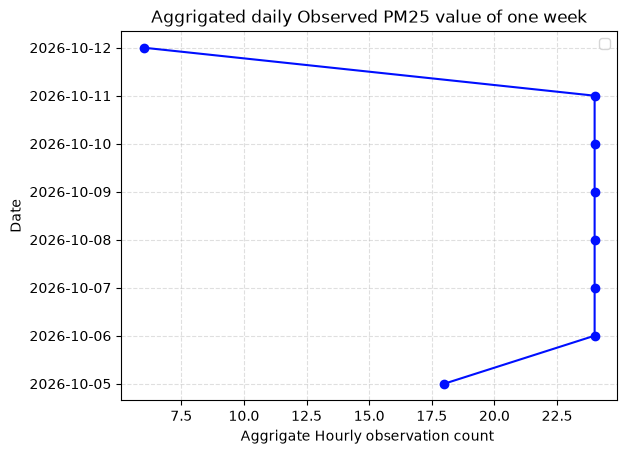

In [24]:
# Line plot
plt.plot(daily1['hourly_observation_count'], daily1['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count ')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed PM25 value of one week")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 3. Data Analysis and visualization of last 24 hours

In [31]:
df24 = pd.read_csv('cleaned_bagdolLast24hours.csv')
df24

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6230465,Bagdol,pm25,28.8,µg/m³,2026-10-11 06:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-11,06:45:00
1,6230465,Bagdol,pm25,31.9,µg/m³,2026-10-11 07:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-11,07:45:00
2,6230465,Bagdol,pm25,34.0,µg/m³,2026-10-11 08:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-11,08:45:00
3,6230465,Bagdol,pm25,42.5,µg/m³,2026-10-11 09:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-11,09:45:00
4,6230465,Bagdol,pm25,40.7,µg/m³,2026-10-11 10:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-11,10:45:00
5,6230465,Bagdol,pm25,32.2,µg/m³,2026-10-11 11:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-11,11:45:00
6,6230465,Bagdol,pm25,25.1,µg/m³,2026-10-11 12:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-11,12:45:00
7,6230465,Bagdol,pm25,20.8,µg/m³,2026-10-11 13:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-11,13:45:00
8,6230465,Bagdol,pm25,24.6,µg/m³,2026-10-11 14:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-11,14:45:00
9,6230465,Bagdol,pm25,27.7,µg/m³,2026-10-11 15:45:00+05:45,Asia/Kathmandu,27.671706,85.301619,KIAS,AirGradient,2026-10-11,15:45:00


In [32]:
df24['time'].unique()

<ArrowStringArray>
['06:45:00', '07:45:00', '08:45:00', '09:45:00', '10:45:00', '11:45:00',
 '12:45:00', '13:45:00', '14:45:00', '15:45:00', '16:45:00', '17:45:00',
 '18:45:00', '19:45:00', '20:45:00', '21:45:00', '22:45:00', '23:45:00',
 '00:45:00', '01:45:00', '02:45:00', '03:45:00', '04:45:00', '05:45:00']
Length: 24, dtype: str

In [33]:
df24.columns

Index(['location_id', 'location_name', 'parameter', 'value', 'unit',
       'datetimeLocal', 'timezone', 'latitude', 'longitude', 'owner_name',
       'provider', 'date', 'time'],
      dtype='str')

### Plotting hourly data 

/tmp/ipykernel_6364/1036584907.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


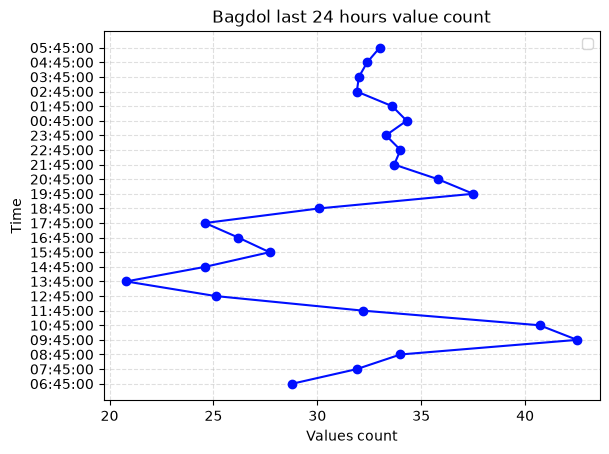

In [42]:
# Line Plot
plt.plot(df24['value'], df24['time'], color='#000fff', marker='o')
plt.xlabel('Values count')
plt.ylabel('Time')
plt.title('Bagdol last 24 hours value count')
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()